# Análisis exploratorio de datos

Contentesta las siguientes preguntas escribiendo el código de Python necesario para encontrar las respuestas o producir las gráficas necesarias

---


In [1]:
# No mostrar advertencias
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Estilo visual para las gráficas
sns.set_theme(style="whitegrid")

# Cargar el dataset
df = pd.read_csv('data/retailmax.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### 1. ¿Cuál es la distribución de edades de los clientes?
- **Objetivo**: Comprender la distribución de las edades en el conjunto de datos.
- **Respuesta esperada**: Un histograma de la columna Age.

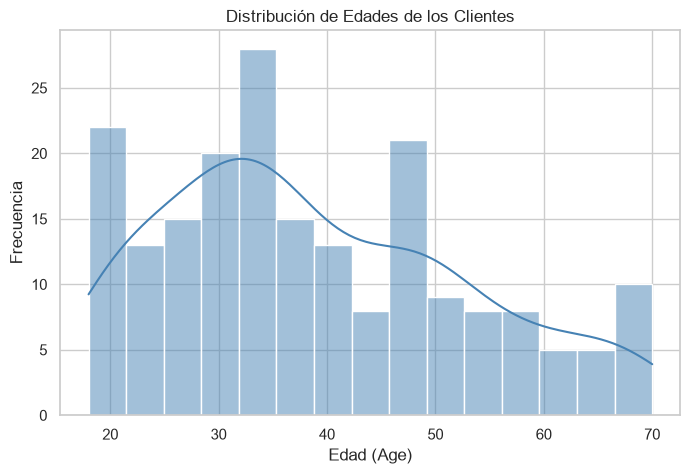

In [2]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', bins=15, kde=True, color='steelblue')
plt.title('Distribución de Edades de los Clientes')
plt.xlabel('Edad (Age)')
plt.ylabel('Frecuencia')
plt.show()

### 2. ¿Existen diferencias significativas en los ingresos anuales entre hombres y mujeres?
- **Objetivo**: Comparar la distribución de ingresos anuales entre géneros.
- **Respuesta esperada**: Una gráfica de cajas (boxplot) que muestre la distribución de Annual Income (k$) por género.

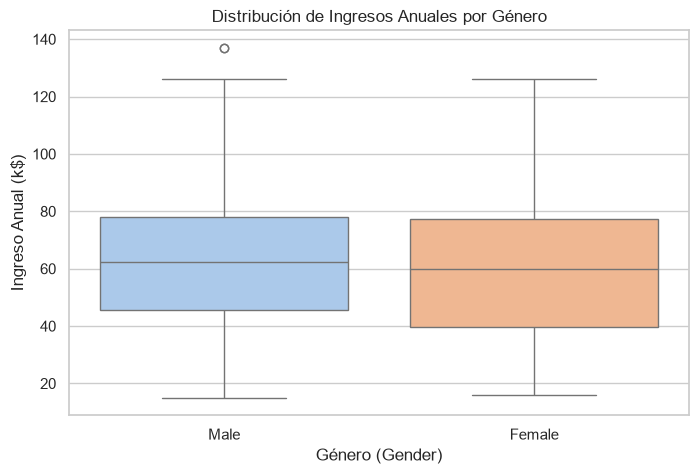

In [3]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Gender', y='Annual Income (k$)', palette='pastel')
plt.title('Distribución de Ingresos Anuales por Género')
plt.xlabel('Género (Gender)')
plt.ylabel('Ingreso Anual (k$)')
plt.show()

### 3. ¿Cómo se distribuye la puntuación de gasto (Spending Score) entre los diferentes rangos de edad?
- **Objetivo**: Analizar la relación entre la edad y la puntuación de gasto.
- **Respuesta esperada**: Una gráfica de dispersión (scatter plot) o un gráfico de cajas que compare la Spending Score (1-100) con diferentes grupos de edad.

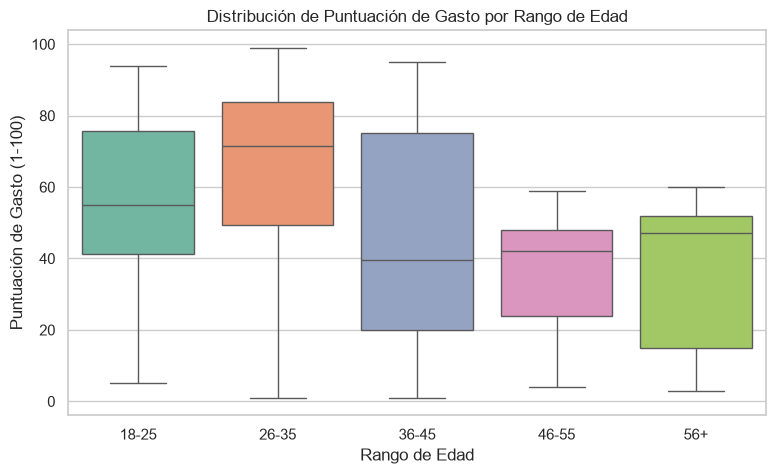

In [4]:
df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[17, 25, 35, 45, 55, 75],
    labels=['18-25', '26-35', '36-45', '46-55', '56+']
)

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Age_Group', y='Spending Score (1-100)', palette='Set2')
plt.title('Distribución de Puntuación de Gasto por Rango de Edad')
plt.xlabel('Rango de Edad')
plt.ylabel('Puntuación de Gasto (1-100)')
plt.show()

### 4. ¿Cuál es la correlación entre el ingreso anual y la puntuación de gasto?
- **Objetivo**: Identificar si existe una relación lineal entre el ingreso y el gasto.
- **Respuesta esperada**: Una gráfica de dispersión y el cálculo del coeficiente de correlación entre Annual Income (k$) y Spending Score (1-100).

Coeficiente de correlación de Pearson: 0.0099


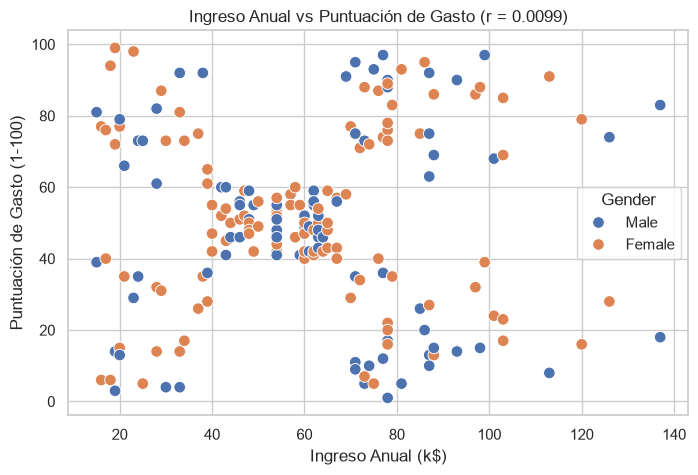

In [5]:
correlacion = df['Annual Income (k$)'].corr(df['Spending Score (1-100)'])
print(f"Coeficiente de correlación de Pearson: {correlacion:.4f}")

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', hue='Gender', s=70)
plt.title(f'Ingreso Anual vs Puntuación de Gasto (r = {correlacion:.4f})')
plt.xlabel('Ingreso Anual (k$)')
plt.ylabel('Puntuación de Gasto (1-100)')
plt.show()

### 5. ¿Cómo varía la puntuación de gasto en diferentes grupos de ingresos anuales?
- **Objetivo**: Examinar cómo los clientes en diferentes rangos de ingresos se comportan en términos de gasto.
- **Respuesta esperada**: Una gráfica de cajas o de violín que muestre la Spending Score (1-100) para diferentes rangos de Annual Income (k$).

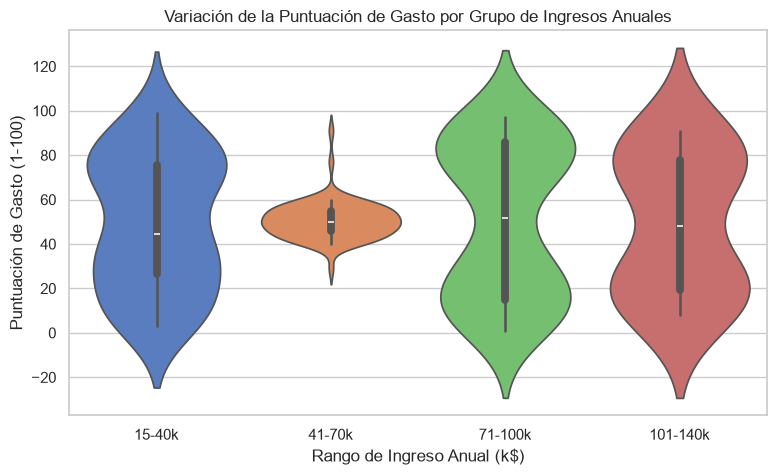

In [6]:
df['Income_Group'] = pd.cut(
    df['Annual Income (k$)'],
    bins=[10, 40, 70, 100, 140],
    labels=['15-40k', '41-70k', '71-100k', '101-140k']
)

plt.figure(figsize=(9, 5))
sns.violinplot(data=df, x='Income_Group', y='Spending Score (1-100)', palette='muted', inner='box')
plt.title('Variación de la Puntuación de Gasto por Grupo de Ingresos Anuales')
plt.xlabel('Rango de Ingreso Anual (k$)')
plt.ylabel('Puntuación de Gasto (1-100)')
plt.show()

### 6. ¿Cuál es la proporción de clientes por género?
- **Objetivo**: Determinar el balance de género en el conjunto de datos.
- **Respuesta esperada**: Una gráfica de barras o un gráfico de pastel que muestre la proporción de hombres y mujeres.

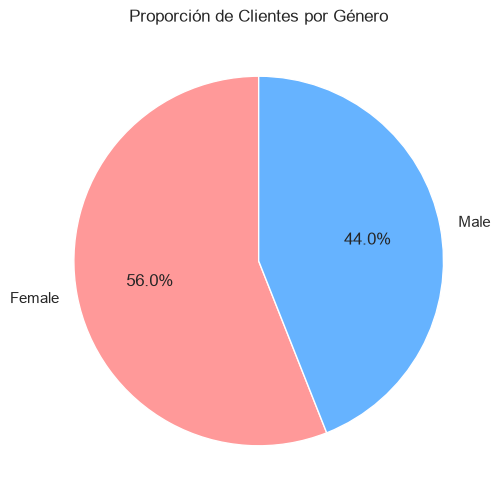

In [7]:
conteo_genero = df['Gender'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    conteo_genero,
    labels=conteo_genero.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#ff9999', '#66b3ff']
)
plt.title('Proporción de Clientes por Género')
plt.show()

### 7. ¿Qué grupos de edad gastan más en promedio?
- **Objetivo**: Identificar los grupos de edad que tienen una mayor puntuación de gasto en promedio.
- **Respuesta esperada**: Una gráfica de barras que compare la puntuación de gasto promedio entre diferentes grupos de edad.

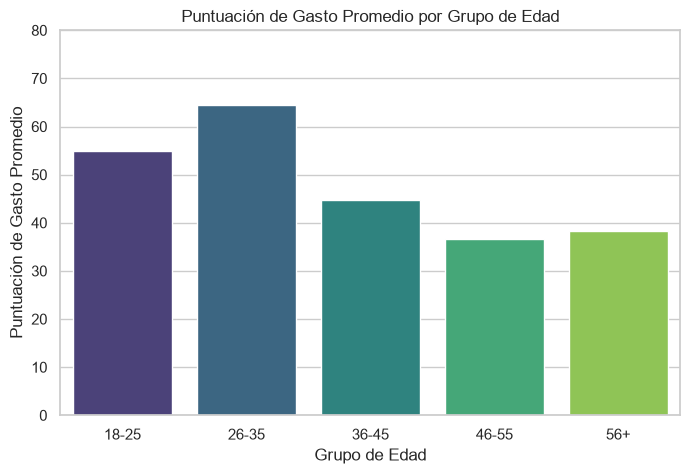

In [8]:
gasto_promedio_edad = df.groupby('Age_Group', observed=False)['Spending Score (1-100)'].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=gasto_promedio_edad, x='Age_Group', y='Spending Score (1-100)', palette='viridis')
plt.title('Puntuación de Gasto Promedio por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Puntuación de Gasto Promedio')
plt.ylim(0, 80)
plt.show()

### 8. ¿Hay alguna relación entre la edad y el ingreso anual de los clientes?
- **Objetivo**: Explorar si hay una tendencia entre la edad de los clientes y sus ingresos.
- **Respuesta esperada**: Una gráfica de dispersión que muestre la relación entre Age y Annual Income (k$).

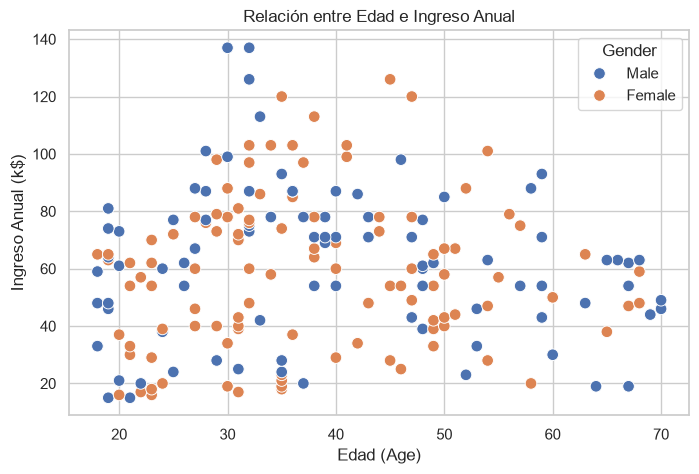

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Age', y='Annual Income (k$)', hue='Gender', s=70)
plt.title('Relación entre Edad e Ingreso Anual')
plt.xlabel('Edad (Age)')
plt.ylabel('Ingreso Anual (k$)')
plt.show()

### 9. ¿Cuál es la distribución conjunta de la edad y el ingreso anual?
- **Objetivo**: Entender cómo se distribuyen estas dos variables en conjunto.
- **Respuesta esperada**: Una gráfica de dispersión con una densidad de puntos o un gráfico de hexágonos que muestre la distribución conjunta de Age y Annual Income (k$).

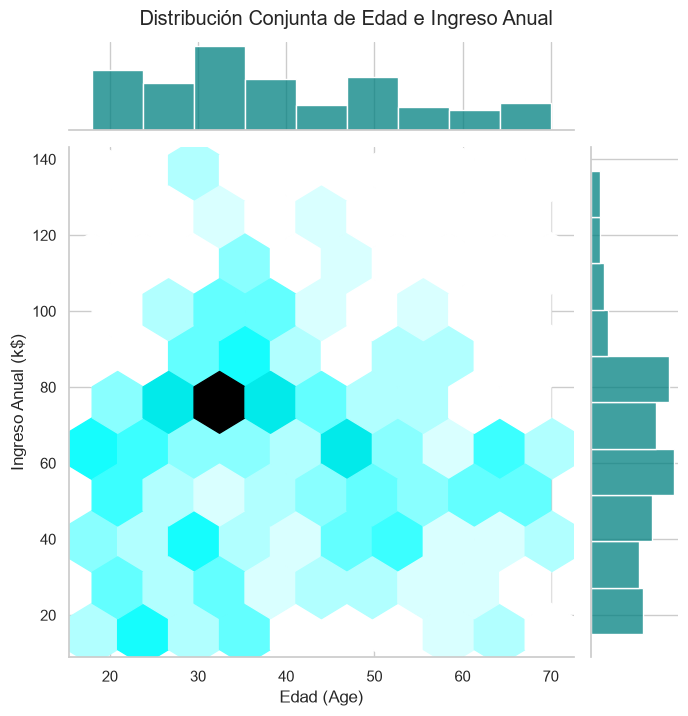

In [10]:
g = sns.jointplot(
    data=df,
    x='Age',
    y='Annual Income (k$)',
    kind='hex',
    color='teal',
    height=7
)
g.set_axis_labels('Edad (Age)', 'Ingreso Anual (k$)')
g.fig.suptitle('Distribución Conjunta de Edad e Ingreso Anual', y=1.02)
plt.show()

### 10. ¿Cómo se distribuyen los clientes en función de la puntuación de gasto y el género?
- **Objetivo**: Analizar la relación entre la puntuación de gasto y el género.
- **Respuesta esperada**: Una gráfica de dispersión o un gráfico de violín que muestre la Spending Score (1-100) separada por género.

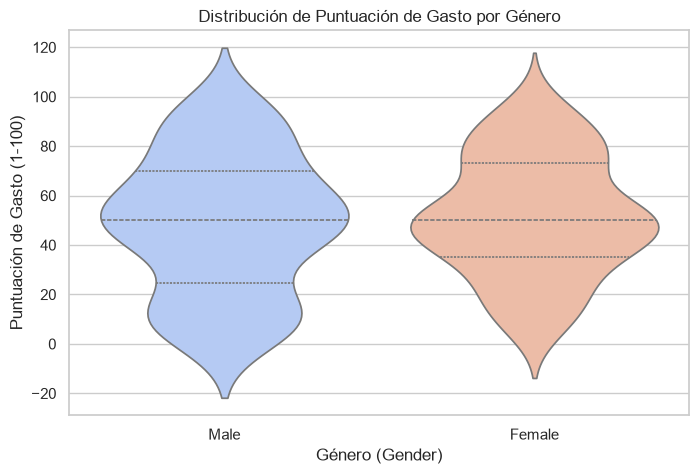

In [11]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x='Gender', y='Spending Score (1-100)', palette='coolwarm', inner='quartile')
plt.title('Distribución de Puntuación de Gasto por Género')
plt.xlabel('Género (Gender)')
plt.ylabel('Puntuación de Gasto (1-100)')
plt.show()